# Parte 1 – Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| Configuración | Valor |
|---|---|
| Fecha de extracción | 27/10/2026 |
| Documentos | 25 de Wikimedia Commons: 8 impresos nítidos, 8 fotos con sombra o inclinación, 9 manuscritos |
| Audio | 8 grabaciones de Wikimedia Commons (español peruano, cortadas en 33 clips de ≤ 60 s) + 120 oraciones de OpenSLR 73 (`es_pe_female` / `es_pe_male`) |
| Licencias | Dominio público, CC0, CC BY 2.0/4.0 y CC BY-SA 4.0 (detalle por archivo en `datos/fuentes.csv` y `datos/atribucion.csv`) |
| OCR | PaddleOCR 3.7.0 (PP-OCRv6, `lang="es"`, configuración por defecto) sobre paddlepaddle 3.3.1, motor onnxruntime 1.31.0 |
| ASR | faster-whisper 1.2.1 (CTranslate2 4.8.2) modelo `small`, int8 en CPU, VAD Silero activado |
| Diarización | pyannote.audio 4.0.7 (huellas WeSpeaker) + clustering aglomerativo de `voz.py` (sesión 13) |
| NER (seudonimización) | `mrm8488/bert-spanish-cased-finetuned-ner` con transformers 5.16.1 (torch 2.13.0) |
| Entornos del curso | equivalentes a `uv sync --group docai` y `uv sync --group audio`; versiones exactas en `requirements-notebooks.txt` |

**Decisiones documentadas**
- **Motor de PaddleOCR:** onnxruntime, con los mismos modelos PP-OCRv6. En Windows con CPU, el backend oneDNN de Paddle falla con PP-OCRv6 (`NotImplementedError`), y sin oneDNN tarda 114 s por página. onnxruntime tarda 28 s y devuelve las mismas cajas.
- **Modelo de ASR del corpus:** `small`. turbo proyectaba más de una hora de CPU para 40 minutos de audio en esta laptop. turbo y Parakeet se comparan sobre la muestra en el notebook 02.
- **Seudonimización:**
  - Se reemplazan las personas **privadas** y cualquier DNI, celular, correo o RUC de persona natural.
  - Se conservan las autoridades que firman en su cargo, los personajes históricos y los dirigentes en conferencia de prensa.
  - Los candidatos salen del NER y los clasifica una persona.
  - El diccionario con los nombres reales no se versiona.
- **Descargas:**
  - User-Agent descriptivo, pausa de 1–2 s y `robots.txt` revisado por host.
  - La API de Commons (metadatos y licencias) se rige por su política de uso, [API:Etiquette](https://www.mediawiki.org/wiki/API:Etiquette).

In [1]:
import json, sys, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import soundfile as sf

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
import corpus as c, ocr, privacidad as pv, voz
import paddleocr
import paleta  # registra la plantilla de Plotly "paleta"

pio.templates.default = "paleta"
pio.renderers.default = "plotly_mimetype+png"   # PNG embebido para que GitHub muestre los gráficos
REPROCESAR = False   # True vuelve a descargar y a correr OCR/ASR (horas de CPU); False usa la caché de datos/raw/
RAW = c.RAW
pd.set_option("display.max_colwidth", 80)

C:\Users\DOKU\Documents\GitHub\intermediate-python-hw\tarea_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Corpus, licencias y atribución

Una sola tabla (`corpus.DOCUMENTOS` y `corpus.GRABACIONES`) genera `fuentes.csv` y `atribucion.csv`.
- La licencia, el autor y el `pageid` de cada archivo se leen de la API de Commons.
- El enlace de atribución usa `?curid=<pageid>`, así ninguna URL publicada lleva el nombre de una persona privada.
- Las descripciones son propias.

In [2]:
docs = pd.DataFrame(c.DOCUMENTOS, columns=["id", "tipo", "ruta", "epoca", "descripcion"])
recs = pd.DataFrame(c.GRABACIONES, columns=["grabacion", "ruta", "descripcion", "hablantes_declarados"])
cache_meta = RAW / "metadatos_commons.csv"
meta = pd.read_csv(cache_meta) if cache_meta.exists() else pd.DataFrame(columns=["titulo"])
faltan = [r for r in list(docs.ruta) + list(recs.ruta) if c.titulo_commons(r) not in set(meta.titulo)]
if faltan:
    meta = pd.concat([meta, c.metadatos_commons(faltan)], ignore_index=True).drop_duplicates("titulo")
    meta.to_csv(cache_meta, index=False)
meta = meta.set_index("titulo")
for t in (docs, recs):
    t["titulo"] = t.ruta.map(c.titulo_commons)
    t["licencia"] = t.titulo.map(meta.licencia)
    t["autor"] = t.titulo.map(meta.autor).fillna("")
    t["pageid"] = t.titulo.map(meta.pageid).astype(int)
    t["fecha_original"] = t.titulo.map(meta.fecha_original).fillna("")
print(docs.groupby(["tipo", "licencia"]).size().to_string())
print(recs[["grabacion", "licencia"]].to_string(index=False))

tipo        licencia     
foto        CC BY 2.0        1
            CC BY-SA 4.0     5
            CC0              2
impreso     CC BY 4.0        2
            Public domain    6
manuscrito  CC0              1
            Public domain    8
grabacion     licencia
   rec_01 CC BY-SA 4.0
   rec_02 CC BY-SA 4.0
   rec_03 CC BY-SA 4.0
   rec_04 CC BY-SA 4.0
   rec_05 CC BY-SA 4.0
   rec_06 CC BY-SA 4.0
   rec_07 CC BY-SA 4.0
   rec_08 CC BY-SA 4.0


In [3]:
slr = pd.read_csv(RAW / "audio" / "openslr73" / "seleccion.csv")
clips = pd.read_csv(RAW / "audio" / "clips.csv")
hoy = "2026-10-26"
fuentes = pd.concat([
    pd.DataFrame({"id": docs.id, "modalidad": "documento",
                  "fuente_url": "https://commons.wikimedia.org/?curid=" + docs.pageid.astype(str),
                  "licencia": docs.licencia, "acceso": "descarga directa del archivo original desde fuente_url",
                  "titulo": docs.descripcion, "autor": docs.autor, "fecha_original": docs.fecha_original,
                  "fecha_extraccion": hoy}),
    pd.DataFrame({"id": clips.id, "modalidad": "audio",
                  "fuente_url": clips.grabacion.map(dict(zip(recs.grabacion, "https://commons.wikimedia.org/?curid=" + recs.pageid.astype(str))))
                                .fillna("https://www.openslr.org/73/"),
                  "licencia": clips.grabacion.map(dict(zip(recs.grabacion, recs.licencia))).fillna("CC BY-SA 4.0"),
                  "acceso": [f"grabación {g} de fuente_url, tramo {a:.2f}–{b:.2f} s" if f == "Wikimedia Commons"
                             else f"{z}: {g}.wav (lectura por HTTP Range)" for f, g, a, b, z in
                             zip(clips.fuente, clips.grabacion, clips.inicio_seg, clips.fin_seg,
                                 clips.grabacion.map(dict(zip(slr.archivo, slr.zip))))],
                  "titulo": clips.grabacion.map(dict(zip(recs.grabacion, recs.descripcion))).fillna("Oración leída de OpenSLR 73 (español peruano)"),
                  "autor": clips.grabacion.map(dict(zip(recs.grabacion, recs.autor))).fillna("Google (OpenSLR 73)"),
                  "fecha_original": clips.grabacion.map(dict(zip(recs.grabacion, recs.fecha_original))).fillna("2019"),
                  "fecha_extraccion": hoy}),
], ignore_index=True)
atribucion = pd.concat([
    pd.DataFrame({"archivo": docs.id + docs.ruta.map(lambda r: Path(r).suffix.lower()), "idioma": "es",
                  "descripcion": docs.descripcion, "autor": docs.autor, "licencia": docs.licencia,
                  "fuente": "https://commons.wikimedia.org/?curid=" + docs.pageid.astype(str)}),
    pd.DataFrame({"archivo": recs.grabacion + recs.ruta.map(lambda r: Path(r).suffix.lower()), "idioma": "es",
                  "descripcion": recs.descripcion, "autor": recs.autor, "licencia": recs.licencia,
                  "fuente": "https://commons.wikimedia.org/?curid=" + recs.pageid.astype(str)}),
    pd.DataFrame([{"archivo": "es_pe_female.zip, es_pe_male.zip (120 oraciones)", "idioma": "es",
                   "descripcion": "Crowdsourced high-quality Peruvian Spanish speech data set (OpenSLR 73)",
                   "autor": "Google", "licencia": "CC BY-SA 4.0", "fuente": "https://www.openslr.org/73/"}]),
], ignore_index=True)
print(fuentes.shape, atribucion.shape)
fuentes.head()

(178, 9) (34, 6)


,id,modalidad,fuente_url,licencia,acceso,titulo,autor,fecha_original,fecha_extraccion
0,doc_001,documento,https://commons.wikimedia.org/?curid=179771570,CC BY 4.0,descarga directa del archivo original desde fuente_url,Decreto Supremo 001-81-AA que declara el Santuario Histórico de Machu Picchu...,Diario Oficial El Peruano,1981-01-12,2026-10-26
1,doc_002,documento,https://commons.wikimedia.org/?curid=88315184,Public domain,descarga directa del archivo original desde fuente_url,"Decreto Supremo 046-2020-PCM sobre el toque de queda por COVID-19, p. 1",Presidencia del Consejo de Ministros del Perú,2020-03-18,2026-10-26
2,doc_003,documento,https://commons.wikimedia.org/?curid=82973298,Public domain,descarga directa del archivo original desde fuente_url,"Decreto de Urgencia 002-2019 sobre las elecciones congresales, p. 1",Presidencia de la República del Perú,2019-10-09,2026-10-26
3,doc_004,documento,https://commons.wikimedia.org/?curid=88146070,Public domain,descarga directa del archivo original desde fuente_url,Folleto del MINSA/DIGESA sobre limpieza y desinfección en domicilios (2020),Ministerio de Salud del Perú,2020-03-15,2026-10-26
4,doc_005,documento,https://commons.wikimedia.org/?curid=88316494,Public domain,descarga directa del archivo original desde fuente_url,Comunicado oficial N.° 21 del MINSA (2020),Ministerio de Salud del Perú,2020-03-19,2026-10-26


## 2. Descarga, preparación y cortes de audio

- **Documentos:** los PDF se rasterizan a 200 dpi (página 1) con `pypdfium2`, como en `preparar.py` de la sesión 10.
- **Audio:** se pasa a mono de 16 kHz con `voz.cargar_audio`.
- **Clips:** las grabaciones largas se cortan en clips de ≤ 60 s **solo con el VAD**, en la mitad de una pausa. Los cortes cubren toda la grabación.
- **OpenSLR 73:** se lee por HTTP Range, sin bajar los zips de ~1 GB: 4 oraciones por hablante, de 15 hablantes por sexo (semilla 7).

In [4]:
if REPROCESAR:
    for r in docs.itertuples():
        o = c.descargar(r.ruta, RAW / "documentos" / "originales" / f"{r.id}{Path(r.ruta).suffix.lower()}")
        c.rasterizar(o, RAW / "documentos" / "img" / f"{r.id}.png")
docs["archivo"] = [f"datos/raw/documentos/img/{i}.png" for i in docs.id]
docs["sha256"] = [c.sha256(RAIZ / a) for a in docs.archivo]
clips["archivo_audio"] = [f"datos/raw/audio/clips/{i}.wav" for i in clips.id]
clips["sha256"] = [c.sha256(RAIZ / a) for a in clips.archivo_audio]
print("Documentos en disco:", sum((RAIZ / a).exists() for a in docs.archivo), "de", len(docs))
print("Clips en disco:", sum((RAIZ / a).exists() for a in clips.archivo_audio), "de", len(clips))
print("Minutos de audio:", round(clips.duracion_seg.sum() / 60, 1))
clips.groupby("fuente").agg(clips=("id", "size"), minutos=("duracion_seg", lambda s: round(s.sum() / 60, 1)),
                            max_seg=("duracion_seg", "max"))

Documentos en disco: 25 de 25
Clips en disco: 153 de 153
Minutos de audio: 40.6


,clips,minutos,max_seg
fuente,,,
OpenSLR 73,120,13.4,14.17
Wikimedia Commons,33,27.3,59.63


## 3. OCR con PaddleOCR (configuración por defecto)

`PaddleOCR(lang="es", engine="onnxruntime")` deja activados, de fábrica, la orientación del documento, el *unwarping* (UVDoc) y la orientación de línea.
- El respaldo crudo de cada documento (JSON de `predict` e imagen con cajas) queda en `datos/raw/documentos/paddle/<id>/`.
- `texto_ocr` une las cajas en **renglones** (solapamiento vertical > 50 %) y los ordena de arriba hacia abajo y de izquierda a derecha (`ocr.orden_lectura`).

In [5]:
salida_ocr = RAW / "ocr" / "corpus_paddle_base.csv"
if REPROCESAR or not salida_ocr.exists():
    lector = ocr.crear_paddle(geometria=True)
    pd.DataFrame([{"id": i, **ocr.leer_paddle(lector, RAIZ / a, RAW / "documentos" / "paddle" / i)}
                  for i, a in zip(docs.id, docs.archivo)]).to_csv(salida_ocr, index=False)
res_ocr = pd.read_csv(salida_ocr)
docs = docs.merge(res_ocr, on="id")
docs["n_caracteres"] = docs.texto.fillna("").str.len()
docs.groupby("tipo").agg(documentos=("id", "size"), cajas_media=("n_cajas", "mean"),
                         puntaje_medio=("puntaje_medio", "mean"), segundos_media=("segundos", "mean")).round(2)

,documentos,cajas_media,puntaje_medio,segundos_media
tipo,,,,
foto,8,143.75,0.90,45.63
impreso,8,84.62,0.99,40.64
manuscrito,9,22.22,0.69,18.50


doc_002 impreso


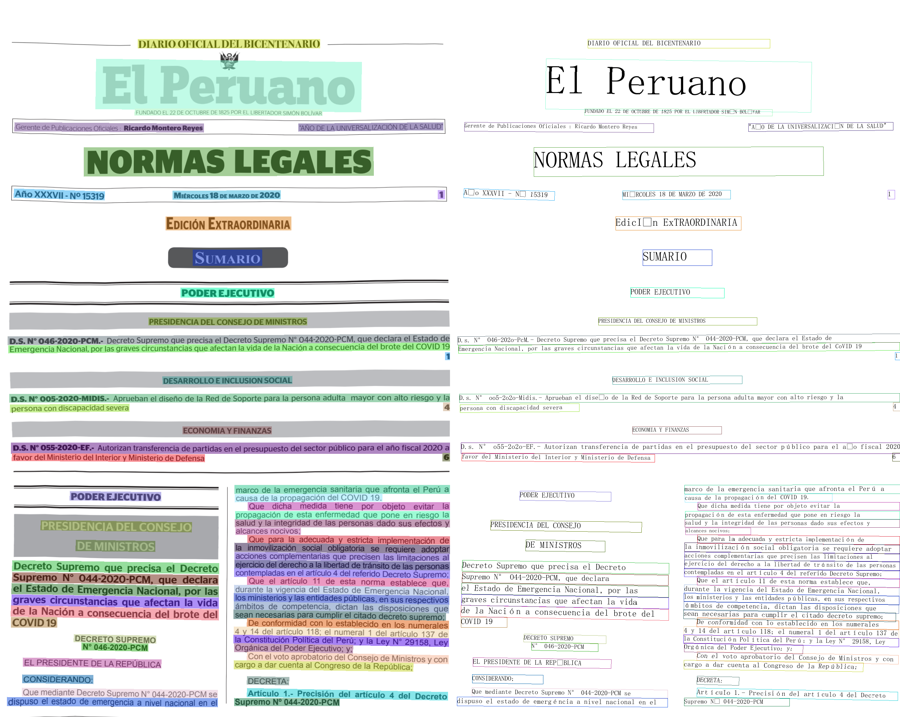

doc_009 foto


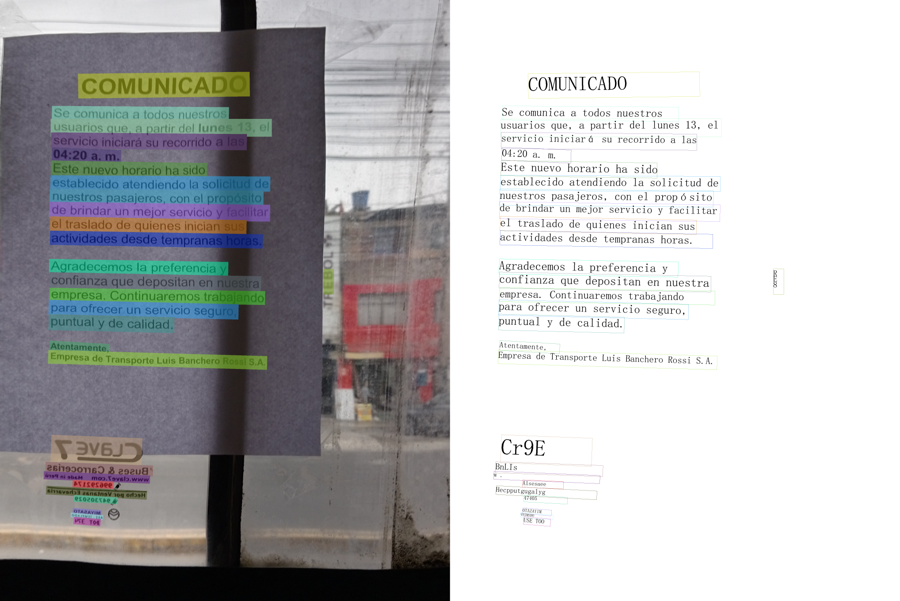

doc_021 manuscrito


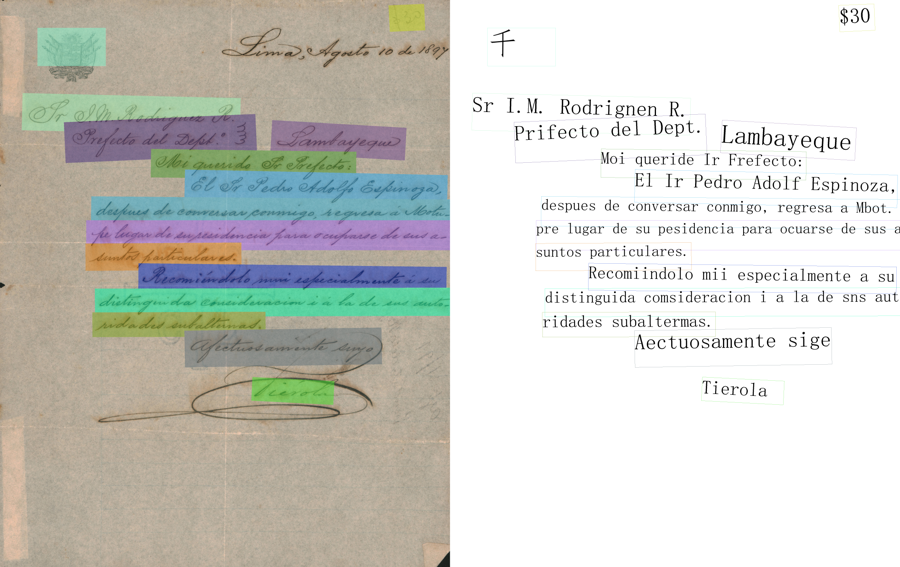

In [6]:
from PIL import Image
from IPython.display import display
for i in ["doc_002", "doc_009", "doc_021"]:   # un impreso, una foto y un manuscrito
    img = next((RAW / "documentos" / "paddle" / i).glob("*ocr_res_img*"), None)
    if img:
        im = Image.open(img); im.thumbnail((900, 900)); print(i, docs.set_index("id").tipo[i]); display(im)

## 4. ASR: VAD + faster-whisper + diarización

- Cada grabación de Commons se transcribe **completa**. faster-whisper usa su VAD (Silero) para no transcribir silencios, que es donde Whisper alucina frases.
- `voz.diarizar` asigna los hablantes: huellas WeSpeaker + clustering aglomerativo con el umbral por defecto 0.7, sin fijar el número de hablantes.
- Los segmentos se reparten entre los clips por su punto medio. `n_hablantes` = hablantes distintos dentro del clip, y la numeración es la de la grabación.
- Se exporta un CSV de segmentos y, por grabación, el SRT y el TXT. Los crudos quedan en `datos/raw/`; los seudonimizados, en `datos/salidas_asr/`.

In [7]:
if REPROCESAR:
    raise SystemExit("Correr el ASR completo con REPROCESAR=True tarda más de 30 min de CPU; ver voz.Transcriptor")
segs = pd.read_csv(RAW / "asr" / "segmentos_crudos.csv")
txt = pd.read_csv(RAW / "asr" / "textos_clips_crudos.csv")
clips = clips.merge(txt, on="id", how="left")
resumen = segs.groupby("grabacion").agg(segmentos=("texto", "size"), hablantes_detectados=("hablante", "nunique"))
resumen["hablantes_declarados"] = resumen.index.map(dict(zip(recs.grabacion, recs.hablantes_declarados)))
print("Clips con 2 o más hablantes:", int((clips.n_hablantes >= 2).sum()))
resumen

Clips con 2 o más hablantes: 21


,segmentos,hablantes_detectados,hablantes_declarados
grabacion,,,
rec_01,27,2,2.0
rec_02,29,1,3.0
rec_03,47,2,NaN
rec_04,14,2,NaN
rec_05,25,5,NaN
rec_06,31,3,NaN
rec_07,86,3,NaN
rec_08,240,3,NaN


## 5. Seudonimización

1. **Regex:** DNI, celular, correo y RUC de persona natural se reemplazan por `[DNI]`, `[TELEFONO]`, `[CORREO]` y `[RUC]`.
2. **NER:** `mrm8488/bert-spanish-cased-finetuned-ner` (`PER`, confianza ≥ 0.6) propone candidatos sobre los OCR, los ASR y las salidas de los modelos de la muestra. Cuando estuvieron listas las referencias manuales, se corrió también sobre ellas (`candidatos_referencias.csv`).
3. **Revisión humana** en `herramientas/estacion_manual.py`: privado, público o no es persona. En la misma revisión se marca qué imágenes y audios se pueden publicar: no se publica ninguno en el que se vea o se oiga el nombre de una persona privada.
4. `voz.seudonimizar` (difuso, rapidfuzz ≥ 85) reemplaza los privados por `[PERSONA_n]`.

Este notebook imprime solo texto seudonimizado o conteos.

In [8]:
cand = pd.read_csv(RAW / "privacidad" / "candidatos.csv")
revision = pd.read_csv(RAW / "privacidad" / "revision.csv")
reemplazos = pv.diccionario(revision)
(RAW / "seudonimos.json").write_text(json.dumps(reemplazos, ensure_ascii=False, indent=1), encoding="utf-8")
print("Candidatos del NER:", len(cand), "| revisión:", revision.clase.value_counts().to_dict())
cand_ref = pd.read_csv(RAW / "privacidad" / "candidatos_referencias.csv")
print("Candidatos en las referencias manuales:", len(cand_ref), "| nuevos (no revisados antes):",
      int(cand_ref.ya_revisado.isna().sum()), "→ un personaje histórico (público), sin reemplazo")
conteo = []
docs["texto_ocr"] = None
for k, t in docs.texto.items():
    docs.at[k, "texto_ocr"], n = pv.seudonimizar(t, reemplazos)
    conteo.append({"modalidad": "documento", "reemplazos": n})
clips["texto_asr_pub"] = None
for k, t in clips.texto_asr.items():
    clips.at[k, "texto_asr_pub"], n = pv.seudonimizar(t, reemplazos)
    conteo.append({"modalidad": "audio", "reemplazos": n})
conteo = pd.DataFrame(conteo)
print("Entidades reemplazadas:", conteo.groupby("modalidad").reemplazos.sum().to_dict())
print("Fugas tras seudonimizar:", pv.fugas(list(docs.texto_ocr.fillna("")) + list(clips.texto_asr_pub.fillna("")), reemplazos, pv.PUBLICOS_EN_METADATOS))

Candidatos del NER: 146 | revisión: {'no_es_persona': 84, 'privado': 39, 'publico': 23}
Candidatos en las referencias manuales: 6 | nuevos (no revisados antes): 1 → un personaje histórico (público), sin reemplazo


Entidades reemplazadas: {'audio': 28, 'documento': 32}


Fugas tras seudonimizar: []


In [9]:
salidas = RAIZ / "datos" / "salidas_asr"
salidas.mkdir(parents=True, exist_ok=True)
for g, s in segs.groupby("grabacion"):
    lista = [voz.Segmento(a, b, pv.seudonimizar(t, reemplazos)[0], f"HABLANTE_{str(h).lstrip('H')}")
             for a, b, t, h in zip(s.inicio, s.fin, s.texto, s.hablante)]
    (salidas / f"{g}.srt").write_text(voz.a_srt(lista), encoding="utf-8")
    (salidas / f"{g}.txt").write_text(voz.a_texto(lista), encoding="utf-8")
seg_pub = segs.assign(texto=[pv.seudonimizar(t, reemplazos)[0] for t in segs.texto],
                      hablante=["HABLANTE_" + str(h).lstrip("H") for h in segs.hablante])
seg_pub.to_csv(RAIZ / "datos" / "segmentos_asr.csv", index=False)
print(sorted(p.name for p in salidas.iterdir()))

['rec_01.srt', 'rec_01.txt', 'rec_02.srt', 'rec_02.txt', 'rec_03.srt', 'rec_03.txt', 'rec_04.srt', 'rec_04.txt', 'rec_05.srt', 'rec_05.txt', 'rec_06.srt', 'rec_06.txt', 'rec_07.srt', 'rec_07.txt', 'rec_08.srt', 'rec_08.txt']


## 6. Limpieza y descartes

- **Duplicados:** se buscan por SHA-256 del archivo.
- **Marcas para revisar** (no descartes automáticos): OCR con menos de 20 caracteres, puntaje medio < 0.5 o clips con menos del 20 % de voz. La decisión es humana: un manuscrito difícil **no** se descarta por fallarle al OCR.
- **Revisión visual previa al sorteo:** se descartaron 5 documentos y 2 reservas, que se reemplazaron por reservas para mantener 8/8/9.

In [10]:
from voz import tramos_de_voz
clips["pct_voz"] = [round(sum(b - a for a, b in tramos_de_voz(sf.read(RAIZ / f, dtype="float32")[0])) / d, 3)
                    for f, d in zip(clips.archivo_audio, clips.duracion_seg)]
dup_docs = docs[docs.duplicated("sha256", keep=False)]
dup_clips = clips[clips.duplicated("sha256", keep=False)]
marcas = pd.concat([docs.loc[(docs.n_caracteres < 20) | (docs.puntaje_medio < 0.5), ["id", "tipo", "n_caracteres", "puntaje_medio"]],
                    clips.loc[clips.pct_voz < 0.2, ["id", "fuente", "pct_voz"]]])
descartes = pd.DataFrame([{"id": f"(antes {slot})", "motivo": motivo, "detalle": c.titulo_commons(ruta), "tipo": tipo}
                          for tipo, ruta, motivo, slot in c.DESCARTES_PREVIOS])
descartes.to_csv(RAIZ / "datos" / "descartes.csv", index=False)
print("Duplicados por hash:", len(dup_docs), "documentos y", len(dup_clips), "clips")
print("Marcados para revisión humana:", len(marcas))
display(marcas)
descartes

Duplicados por hash: 0 documentos y 0 clips
Marcados para revisión humana: 0


,id,tipo,n_caracteres,puntaje_medio,fuente,pct_voz


,id,motivo,detalle,tipo
0,(antes doc_014),casi sin texto legible: afiches fotografiados de lejos,Afiches informativos sobre desastres que ocurrieron en Perú.jpg,foto
1,(antes doc_015),casi sin texto legible: estandarte en un poste,Afiche representativo.jpg,foto
2,(antes doc_016),casi sin texto legible y en inglés,Afiche Museo de Sitio del Parque de la Muralla.jpg,foto
3,(antes doc_017),no es manuscrito: carta mecanografiada (solo la firma es a mano),Carta de César Vallejo a José Carlos Mariátegui.pdf,manuscrito
4,(antes doc_020),no es manuscrito: carta mecanografiada,"4000004161-0016 - Carta de Carlos J. Bachmann. 1914 julio 4, Maldonado; para...",manuscrito
5,(antes doc_014),"reserva descartada: cartel fotografiado de lejos, casi sin texto legible",Cartel del Ministerio de Cultura sobre la Huaca Palomino.jpg,foto
6,(antes doc_015),reserva descartada: señal de ruta con muy poco texto,"Panel informativo Desaguadero, Perú 03.jpg",foto


## 7. Análisis exploratorio

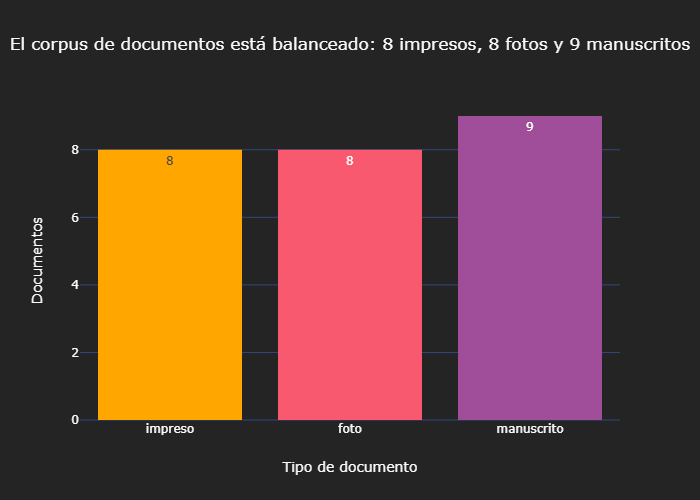

In [11]:
cuenta = docs.tipo.value_counts().reindex(["impreso", "foto", "manuscrito"]).reset_index()
fig = px.bar(cuenta, x="tipo", y="count", text="count", color="tipo", color_discrete_map=paleta.COLORES_TIPO,
             labels={"tipo": "Tipo de documento", "count": "Documentos"},
             title="El corpus de documentos está balanceado: 8 impresos, 8 fotos y 9 manuscritos")
fig.update_layout(showlegend=False)
fig.show()

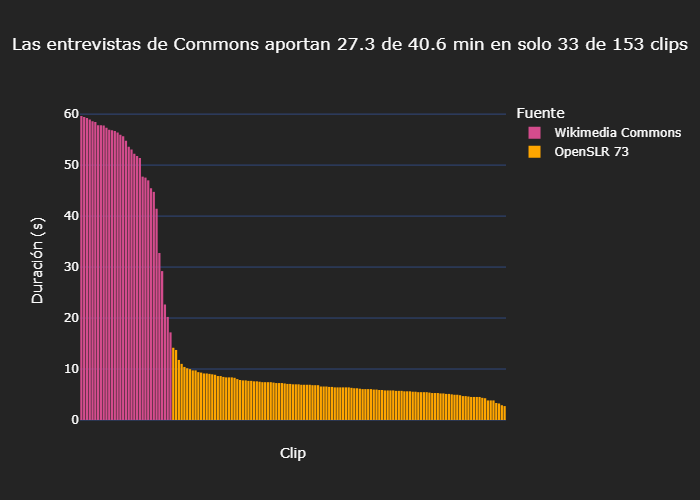

In [12]:
por_fuente = clips.groupby("fuente").duracion_seg.sum().div(60).round(1)
fig = px.bar(clips.sort_values("duracion_seg", ascending=False), x="id", y="duracion_seg", color="fuente",
             color_discrete_map=paleta.COLORES_FUENTE, labels={"duracion_seg": "Duración (s)", "id": "Clip", "fuente": "Fuente"},
             title=(f"Las entrevistas de Commons aportan {por_fuente['Wikimedia Commons']} de {clips.duracion_seg.sum() / 60:.1f} min "
                    f"en solo {(clips.fuente == 'Wikimedia Commons').sum()} de {len(clips)} clips"))
fig.update_xaxes(showticklabels=False)
fig.show()

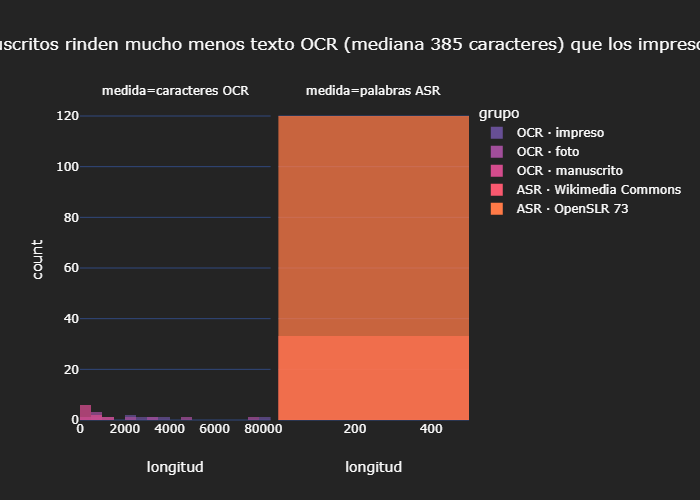

In [13]:
largos = pd.concat([
    pd.DataFrame({"grupo": "OCR · " + docs.tipo, "medida": "caracteres OCR", "longitud": docs.n_caracteres}),
    pd.DataFrame({"grupo": "ASR · " + clips.fuente, "medida": "palabras ASR",
                  "longitud": clips.texto_asr_pub.fillna("").str.replace(r"\[[^\]]*\]", " ", regex=True).str.split().str.len()}),
])
med = docs.groupby("tipo").n_caracteres.median()
fig = px.histogram(largos, x="longitud", color="grupo", facet_col="medida", nbins=30, barmode="overlay", opacity=0.75,
                   color_discrete_sequence=paleta.RAMPA[2:],
                   title=(f"Los manuscritos rinden mucho menos texto OCR (mediana {med['manuscrito']:.0f} caracteres) "
                          f"que los impresos ({med['impreso']:.0f})"))
fig.update_xaxes(matches=None)
fig.show()

## 8. Validación de extremos

¿Los extremos coinciden con las colas de los histogramas? Se muestran los documentos y los clips más largos y más cortos (texto seudonimizado).

In [14]:
cols = ["id", "tipo", "n_caracteres", "puntaje_medio"]
print("OCR más largos:"); display(docs.nlargest(3, "n_caracteres")[cols + ["texto_ocr"]].assign(texto_ocr=lambda d: d.texto_ocr.str[:150]))
print("OCR más cortos:"); display(docs.nsmallest(3, "n_caracteres")[cols + ["texto_ocr"]].assign(texto_ocr=lambda d: d.texto_ocr.str[:150]))
c2 = ["id", "fuente", "duracion_seg", "n_hablantes", "texto_asr_pub"]
print("Clips más largos:"); display(clips.nlargest(3, "duracion_seg")[c2].assign(texto_asr_pub=lambda d: d.texto_asr_pub.str[:150]))
print("Clips más cortos:"); display(clips.nsmallest(3, "duracion_seg")[c2].assign(texto_asr_pub=lambda d: d.texto_asr_pub.str[:150]))

OCR más largos:


,id,tipo,n_caracteres,puntaje_medio,texto_ocr
6,doc_007,impreso,8193,0.987840,Estos cuadros se A\nSE PROCLAMARON LOS CAMPEONES gad L\ndo\nDu\nDE FÚTBOL DE...
9,doc_010,foto,7534,0.896351,ojo e Qe NUEVO SOL HUASCARISTAS'SE 1.50 EL PENSIONISTA UBILADOS DEL PERÚ Com...
10,doc_011,foto,4984,0.908911,51.00 JUNTATUSCUPONESYGANA mlr500 Expreso HOY despidio aprobando Guoinete Ar...


OCR más cortos:


,id,tipo,n_caracteres,puntaje_medio,texto_ocr
22,doc_023,manuscrito,137,0.617328,CAF\n bcd cd atince\nÉl c ane\n t\nd cn nn \ntc n\na faber del Aferes de Si...
21,doc_022,manuscrito,144,0.823626,"$30\nSfor t Anteni Red Ham?\nAreguipa\nChrrids, Abril & fey\nRvel pootaiora ..."
24,doc_025,manuscrito,167,0.692637,"Lima Iuhio, del84s\nDireetr dedhib oua\nemito a l bols de e\nspedidos aconc..."


Clips más largos:


,id,fuente,duracion_seg,n_hablantes,texto_asr_pub
27,clip_028,Wikimedia Commons,59.63,1,"[HABLANTE_1] sino la calidad. ¿Por qué la calidad? La calidad, decimos que n..."
15,clip_016,Wikimedia Commons,59.41,3,"[HABLANTE_1] Buenas noches, soy [PERSONA_2], estudiante de Los San Marcos, ¿..."
1,clip_002,Wikimedia Commons,59.23,2,[HABLANTE_1] ¿Quién gana y a cuánto? ¿Por cuánto? [HABLANTE_2] Es que espera...


Clips más cortos:


,id,fuente,duracion_seg,n_hablantes,texto_asr_pub
102,clip_103,OpenSLR 73,2.73,1,¿En qué calle está la casa?
101,clip_102,OpenSLR 73,2.90,1,En su auto estoy en un botiquín de emergencia.
104,clip_105,OpenSLR 73,3.24,1,¿Cuál es el queso que más te gusta?


In [15]:
cola_corta = docs.nsmallest(3, "n_caracteres").tipo.tolist()
print("Tipos de los 3 OCR más cortos:", cola_corta, "→ coincide con la cola izquierda del histograma (manuscritos)" if
      cola_corta.count("manuscrito") >= 2 else "→ revisar")
print("Los 3 clips más cortos son de:", clips.nsmallest(3, "duracion_seg").fuente.tolist())

Tipos de los 3 OCR más cortos: ['manuscrito', 'manuscrito', 'manuscrito'] → coincide con la cola izquierda del histograma (manuscritos)
Los 3 clips más cortos son de: ['OpenSLR 73', 'OpenSLR 73', 'OpenSLR 73']


## 9. Exportación

`texto_referencia` queda vacío en esta parte. Se completa en el notebook 02, solo para los 10 documentos y los 10 clips de la muestra.

In [16]:
pub = pd.read_csv(RAW / "privacidad" / "publicables.csv").set_index("id")["publicable"]
# los clips de OpenSLR que no estaban en la tabla de revisión se publican salvo que lean un nombre marcado como privado
privados = revision[revision.clase == "privado"].candidato
ids_con_privados = {x.split(":")[-1] for ids in cand[cand.candidato.isin(privados)].ids for x in ids.split()}
por_defecto = (clips.fuente == "OpenSLR 73") & ~clips.id.isin(ids_con_privados)
documentos = pd.DataFrame({
    "id": docs.id, "archivo": docs.archivo, "tipo": docs.tipo,
    "fuente": "Wikimedia Commons (" + docs.licencia + ")", "texto_ocr": docs.texto_ocr,
    "modelo_ocr": f"PaddleOCR {paddleocr.__version__} PP-OCRv6 (lang=es, por defecto, motor onnxruntime, CPU)",
    "texto_referencia": "", "epoca": docs.epoca, "imagen_publicable": docs.id.map(pub).fillna(False).astype(bool),
    "sha256": docs.sha256, "n_caracteres": docs.n_caracteres})
transcripciones = pd.DataFrame({
    "id": clips.id, "archivo_audio": clips.archivo_audio, "duracion_seg": clips.duracion_seg, "idioma": "es",
    "texto_asr": clips.texto_asr_pub,
    "modelo_asr": "faster-whisper small (int8, CPU, VAD on)" + np.where(clips.fuente == "Wikimedia Commons", " + diarización WeSpeaker", ""),
    "n_hablantes": clips.n_hablantes.fillna(1).astype(int), "texto_referencia": "",
    "fuente": clips.fuente, "grabacion": np.where(clips.fuente == "Wikimedia Commons", clips.grabacion, "openslr73"),
    "inicio_seg": clips.inicio_seg, "fin_seg": clips.fin_seg,
    "audio_publicable": clips.id.map(pub).fillna(por_defecto).astype(bool), "pct_voz": clips.pct_voz,
    "sha256": clips.sha256})
documentos.to_csv(RAIZ / "datos" / "documentos.csv", index=False)
transcripciones.to_csv(RAIZ / "datos" / "transcripciones.csv", index=False)
fuentes.to_csv(RAIZ / "datos" / "fuentes.csv", index=False)
atribucion.to_csv(RAIZ / "datos" / "atribucion.csv", index=False)
for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(nombre, df.shape)
documentos.drop(columns=["sha256"]).head()

documentos (25, 11)
transcripciones (153, 15)
fuentes (178, 9)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,epoca,imagen_publicable,n_caracteres
0,doc_001,datos/raw/documentos/img/doc_001.png,impreso,Wikimedia Commons (CC BY 4.0),"DIARIO OFICIAL\nEI Peruano\nNORMAS LEGALES\nLima, Lunes 12 de Enero de 1981\...","PaddleOCR 3.7.0 PP-OCRv6 (lang=es, por defecto, motor onnxruntime, CPU)",,NaN,True,3513
1,doc_002,datos/raw/documentos/img/doc_002.png,impreso,Wikimedia Commons (Public domain),DIARIO OFICIAL DEL BICENTENARIO\nEl Peruano FUNDADO EL 22 DE OCTUBRE DE 1825...,"PaddleOCR 3.7.0 PP-OCRv6 (lang=es, por defecto, motor onnxruntime, CPU)",,NaN,True,2632
2,doc_003,datos/raw/documentos/img/doc_003.png,impreso,Wikimedia Commons (Public domain),DIARIO OFICIAL DEL BICENTENARIO\nEl Peruano\nFUNDADO EL 22 DE OCTUBRE DE 182...,"PaddleOCR 3.7.0 PP-OCRv6 (lang=es, por defecto, motor onnxruntime, CPU)",,NaN,True,3371
3,doc_004,datos/raw/documentos/img/doc_004.png,impreso,Wikimedia Commons (Public domain),Dirección General\nPERÚ Ministerio Viceministerio de Salud Ambiental\nde Sal...,"PaddleOCR 3.7.0 PP-OCRv6 (lang=es, por defecto, motor onnxruntime, CPU)",,NaN,True,1399
4,doc_005,datos/raw/documentos/img/doc_005.png,impreso,Wikimedia Commons (Public domain),PERÙ Ministerio Oficina General\nde Salud de Comunicaciones\nCOMUNICADO OFIC...,"PaddleOCR 3.7.0 PP-OCRv6 (lang=es, por defecto, motor onnxruntime, CPU)",,NaN,True,954


In [17]:
transcripciones.drop(columns=["sha256"]).head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,fuente,grabacion,inicio_seg,fin_seg,audio_publicable,pct_voz
0,clip_001,datos/raw/audio/clips/clip_001.wav,56.85,es,"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va...","faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",2,,Wikimedia Commons,rec_01,0.00,56.85,False,0.831
1,clip_002,datos/raw/audio/clips/clip_002.wav,59.23,es,[HABLANTE_1] ¿Quién gana y a cuánto? ¿Por cuánto? [HABLANTE_2] Es que espera...,"faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",2,,Wikimedia Commons,rec_01,56.85,116.08,True,0.753
2,clip_003,datos/raw/audio/clips/clip_003.wav,20.22,es,"[HABLANTE_2] Es decir, es de dormir arco. [HABLANTE_1] Muchas gracias por su...","faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",2,,Wikimedia Commons,rec_01,116.08,136.30,True,0.859
3,clip_004,datos/raw/audio/clips/clip_004.wav,56.67,es,[HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por ...,"faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",1,,Wikimedia Commons,rec_02,0.00,56.67,False,0.917
4,clip_005,datos/raw/audio/clips/clip_005.wav,57.83,es,[HABLANTE_1] ser más determinante? Antes de que diga su respuesta dígame su ...,"faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",1,,Wikimedia Commons,rec_02,56.67,114.50,False,0.870


In [18]:
fuentes.head()

,id,modalidad,fuente_url,licencia,acceso,titulo,autor,fecha_original,fecha_extraccion
0,doc_001,documento,https://commons.wikimedia.org/?curid=179771570,CC BY 4.0,descarga directa del archivo original desde fuente_url,Decreto Supremo 001-81-AA que declara el Santuario Histórico de Machu Picchu...,Diario Oficial El Peruano,1981-01-12,2026-10-26
1,doc_002,documento,https://commons.wikimedia.org/?curid=88315184,Public domain,descarga directa del archivo original desde fuente_url,"Decreto Supremo 046-2020-PCM sobre el toque de queda por COVID-19, p. 1",Presidencia del Consejo de Ministros del Perú,2020-03-18,2026-10-26
2,doc_003,documento,https://commons.wikimedia.org/?curid=82973298,Public domain,descarga directa del archivo original desde fuente_url,"Decreto de Urgencia 002-2019 sobre las elecciones congresales, p. 1",Presidencia de la República del Perú,2019-10-09,2026-10-26
3,doc_004,documento,https://commons.wikimedia.org/?curid=88146070,Public domain,descarga directa del archivo original desde fuente_url,Folleto del MINSA/DIGESA sobre limpieza y desinfección en domicilios (2020),Ministerio de Salud del Perú,2020-03-15,2026-10-26
4,doc_005,documento,https://commons.wikimedia.org/?curid=88316494,Public domain,descarga directa del archivo original desde fuente_url,Comunicado oficial N.° 21 del MINSA (2020),Ministerio de Salud del Perú,2020-03-19,2026-10-26


### Ejemplos publicables para el dashboard

`datos/ejemplos/` lleva solo lo que la revisión marcó como publicable:
- **Imágenes:** miniaturas JPG de ≤ 1200 px.
- **Audio:** MP3 a 64 kbps de los clips de la muestra de evaluación, uno por grabación de Commons y 10 oraciones de OpenSLR (las 4 de la muestra y 6 sorteadas con semilla 7).

El resto se muestra en el dashboard como texto y metadatos.

In [19]:
import subprocess
from PIL import Image
ejemplos = RAIZ / "datos" / "ejemplos"
ejemplos.mkdir(parents=True, exist_ok=True)
for viejo in ejemplos.glob("*"):
    viejo.unlink()
for i in documentos[documentos.imagen_publicable].id:
    im = Image.open(RAW / "documentos" / "img" / f"{i}.png").convert("RGB")
    im.thumbnail((1200, 1200))
    im.save(ejemplos / f"{i}.jpg", quality=80, optimize=True)
muestra = set(pd.read_csv(RAIZ / "datos" / "muestra_eval.csv").id)
aud = transcripciones[transcripciones.audio_publicable]
commons = aud[aud.fuente == "Wikimedia Commons"]
elegidos = set(commons[commons.id.isin(muestra)].id) | set(commons.groupby("grabacion").id.first())
slr_pub = aud[aud.fuente == "OpenSLR 73"]
elegidos |= set(slr_pub[slr_pub.id.isin(muestra)].id)
elegidos |= set(slr_pub[~slr_pub.id.isin(muestra)].sample(6, random_state=7).id)
for i in sorted(elegidos):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(RAW / "audio" / "clips" / f"{i}.wav"),
                    "-ac", "1", "-b:a", "64k", str(ejemplos / f"{i}.mp3")], check=True)
peso = sum(p.stat().st_size for p in ejemplos.iterdir()) / 2**20
print(len(list(ejemplos.glob("*.jpg"))), "imágenes y", len(list(ejemplos.glob("*.mp3"))), f"audios · {peso:.1f} MB")

21 imágenes y 22 audios · 7.5 MB
